In [ ]:
#LOADING OF DATA




import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#to chheck the file name
df= pd.read_csv('/content/amazon_data.csv')

print("Rows, Columns:", df.shape) #to know the number of rows and columns in the given dataset
print(df.columns.tolist()) #to list all the column names in a list
df.head(3) #to print the first 3 rows

Rows, Columns: (128975, 24)
['index', 'Order ID', 'Date', 'Status', 'Fulfilment', 'Sales Channel ', 'ship-service-level', 'Style', 'SKU', 'Category', 'Size', 'ASIN', 'Courier Status', 'Qty', 'currency', 'Amount', 'ship-city', 'ship-state', 'ship-postal-code', 'ship-country', 'promotion-ids', 'B2B', 'fulfilled-by', 'Unnamed: 22']


/tmp/ipykernel_701/3261744234.py:11: DtypeWarning: Columns (23) have mixed types. Specify dtype option on import or set low_memory=False.
  df= pd.read_csv('/content/amazon_data.csv')


,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Unnamed: 22
0,0,405-8078784-5731545,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,...,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN
1,1,171-9198151-1101146,04-30-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,...,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,NaN
2,2,404-0687676-7273146,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,...,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,NaN


In [ ]:
#CLEANING OD DATA


#1.FIXING THE DATE
df['Date']= pd.to_datetime(df['Date'], errors='coerce')

df['Amount']= pd.to_numeric(df['Amount'], errors='coerce')
df['Qty']= pd.to_numeric(df['Qty'], errors='coerce')

df['Status']= df['Status'].str.strip()
df['Category']= df['Category'].str.strip()
df['ship-state']= df['ship-state'].str.strip()
df['ship-city']= df['ship-city'].str.strip()
df['ship-country']= df['ship-country'].str.strip()

print("Missing Values: ")
print(df.isnull().sum().head(20))
print(df['Status'].value_counts())

/tmp/ipykernel_701/3436603493.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date']= pd.to_datetime(df['Date'], errors='coerce')


Missing Values: 
index                    0
Order ID                 0
Date                     0
Status                   0
Fulfilment               0
Sales Channel            0
ship-service-level       0
Style                    0
SKU                      0
Category                 0
Size                     0
ASIN                     0
Courier Status        6872
Qty                      0
currency              7795
Amount                7795
ship-city               33
ship-state              33
ship-postal-code        33
ship-country            33
dtype: int64
Status
Shipped                          77804
Shipped - Delivered to Buyer     28769
Cancelled                        18332
Shipped - Returned to Seller      1953
Shipped - Picked Up                973
Pending                            658
Pending - Waiting for Pick Up      281
Shipped - Returning to Seller      145
Shipped - Out for Delivery          35
Shipped - Rejected by Buyer         11
Shipping                         

In [ ]:
#1. Total Business
total_sales = df[df['Status']=='Shipped']['Amount'].sum()
total_orders = df[df['Status']=='Shipped'].shape[0]
cancel_rate = (df['Status']== 'Cancelled').mean()*100

print(f"Total Shipped Orders: {total_orders}")
print(f"Total Sales: Rs. {total_sales:,.0f}")
print(f"Cancellation Ratenc : {cancel_rate:.1f}%")

#2. Category wise Sales
cat = df[df['Status']=='Shipped'].groupby('Category')['Amount'].sum().sort_values(ascending=False).head(10)
print("\nTop Category by Sales:")
print(cat)

#3. State wise Orders
print("\nTop 10 states:")
print(df[df['Status']=='Shipped']['ship-state'].value_counts().head(10))

#4. Fulfilment vs Cancellation
print("\nFulfilment vs Cancellation:")
print(pd.crosstab(df['Fulfilment'], df['Status'], normalize='index')*100)



Total Shipped Orders: 77804
Total Sales: Rs. 50,324,255
Cancellation Ratenc : 14.2%

Top Category by Sales:
Category
Set              25574413.0
kurta            14068674.0
Western Dress     5819859.0
Top               3811430.0
Ethnic Dress       549448.0
Blouse             323361.0
Saree               94769.0
Bottom              81386.0
Dupatta               915.0
Name: Amount, dtype: float64

Top 10 states:
ship-state
MAHARASHTRA       13775
KARNATAKA         11020
TAMIL NADU         7150
TELANGANA          6959
UTTAR PRADESH      6193
DELHI              4166
WEST BENGAL        3654
KERALA             3530
ANDHRA PRADESH     3158
HARYANA            2759
Name: count, dtype: int64

Fulfilment vs Cancellation:
Status      Cancelled   Pending  Pending - Waiting for Pick Up   Shipped  \
Fulfilment                                                                 
Amazon      12.788468  0.462664                       0.000000  86.73995   
Merchant    17.468238  0.618683                     

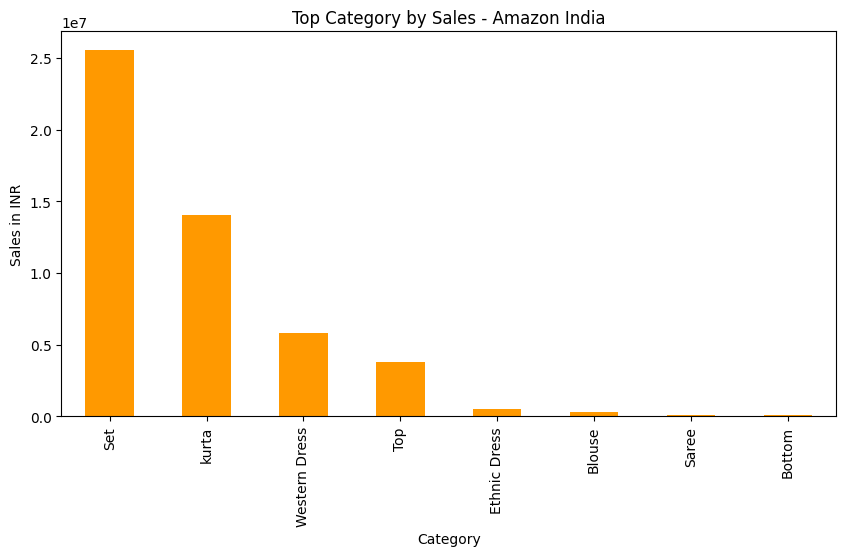

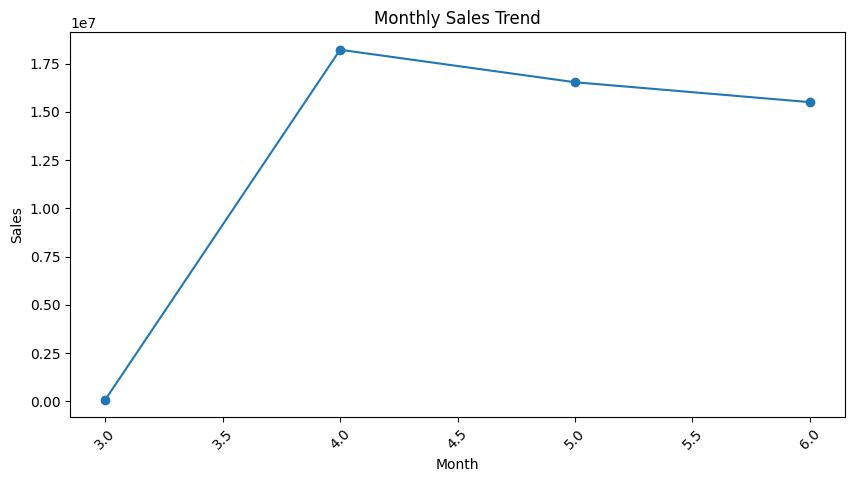

In [ ]:
plt.figure(figsize=(10,5))
df[df['Status']=='Shipped'].groupby('Category')['Amount'].sum().sort_values(ascending=False).head(8).plot(kind= 'bar', color='#FF9900')
plt.title('Top Category by Sales - Amazon India')
plt.ylabel('Sales in INR')
plt.show()

plt.figure(figsize=(10,5))
df['Month'] = df['Date'].dt.month
df[df['Status']=='Shipped'].groupby('Month')['Amount'].sum().plot(kind='line', marker='o')
plt.title('Monthly Sales Trend')
plt.ylabel('Sales')
plt.xticks(rotation=45)
plt.show()